<a href="https://colab.research.google.com/github/trisadhiyanasywa-svg/Praktikum_MachineLearning/blob/TI08_Trisa_0110225049/Praktikum7_ML_Trisa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [5]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [7]:
import pandas as pd
path = '/content/drive/MyDrive/ML 2026/Praktikum07/data//dataset_college.csv'
df = pd.read_csv(path)
df.head()

,StudentID,Gender,Parent_income,IQ,Encourage,Plan
0,4558,male,53900,118,encourage,plan
1,4561,female,24900,87,not encourage,not plan
2,4563,female,65800,93,not encourage,not plan
3,4565,male,11440,117,encourage,plan
4,4567,female,16700,102,not encourage,not plan


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   StudentID      8000 non-null   int64 
 1   Gender         8000 non-null   object
 2   Parent_income  8000 non-null   int64 
 3   IQ             8000 non-null   int64 
 4   Encourage      8000 non-null   object
 5   Plan           8000 non-null   object
dtypes: int64(3), object(3)
memory usage: 375.1+ KB


In [9]:
df.describe()

,StudentID,Parent_income,IQ
count,8000.00000,8000.000000,8000.000000
mean,4000.50000,40584.017500,99.577750
std,2309.54541,18031.506468,18.923655
min,1.00000,4500.000000,60.000000
25%,2000.75000,29400.000000,90.000000
50%,4000.50000,39330.000000,100.000000
75%,6000.25000,51592.500000,110.000000
max,8000.00000,82390.000000,140.000000


In [10]:
print(f"Gender : {df['Gender'].unique()}")
print(f"Encourage : {df['Encourage'].unique()}")
print(f"Plan : {df['Plan'].unique()}")
Gender : ['male' 'female']
Encourage : ['encourage' 'not encourage']
Plan : ['plan' 'not plan']


Gender : ['male' 'female']
Encourage : ['encourage' 'not encourage']
Plan : ['plan' 'not plan']


<Axes: >

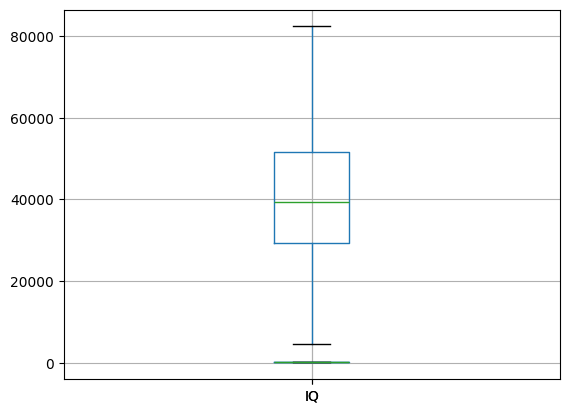

In [11]:
df.boxplot(column=['Parent_income'])
df.boxplot(column=['IQ'])

In [13]:
df['Plan'].value_counts()

,count
Plan,
not plan,5404
plan,2596


In [14]:
df.duplicated().sum()
np.int64(0)

np.int64(0)

In [16]:
df.isnull().sum()

,0
StudentID,0
Gender,0
Parent_income,0
IQ,0
Encourage,0
Plan,0


In [17]:
# Menghapus baris yang memiliki missing values
df = df.dropna().copy()
# One-Hot Encoding
df = pd.get_dummies(
 df,
 columns=['Gender', 'Encourage'],
 dtype=int
)
# Menampilkan hasil cleaning
display(df.head())

,StudentID,Parent_income,IQ,Plan,Gender_female,Gender_male,Encourage_encourage,Encourage_not encourage
0,4558,53900,118,plan,0,1,1,0
1,4561,24900,87,not plan,1,0,0,1
2,4563,65800,93,not plan,1,0,0,1
3,4565,11440,117,plan,0,1,1,0
4,4567,16700,102,not plan,1,0,0,1


In [19]:
X = df[['Parent_income', 'IQ', 'Gender_female', 'Gender_male', 'Encourage_encourage',
'Encourage_not encourage']]
y = df['Plan']
print("Fitur X:", X.columns.tolist())
print("Target y:", y.name)
print("\nDistribusi target Plan:")
print(y.value_counts())

Fitur X: ['Parent_income', 'IQ', 'Gender_female', 'Gender_male', 'Encourage_encourage', 'Encourage_not encourage']
Target y: Plan

Distribusi target Plan:
Plan
not plan    5404
plan        2596
Name: count, dtype: int64


In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
 X, y,
 test_size=0.2,
 random_state=42,
 stratify=y
)
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 6400
Jumlah data testing: 1600


In [22]:
from sklearn.ensemble import RandomForestClassifier

# Membuat model
model = RandomForestClassifier(
 n_estimators=200,                  # Jumlah pohon keputusan  (default 100)
 random_state=42,                   # Menjaga Hasil Tetap Konsisten
 class_weight='balanced',           # Menyeimbangkan bobot kelas minoritas dan mayoritas
 bootstrap = True,                  # Mengambil sampel acak dengan pengembalian
 max_depth = None,                  # Kedalaman pohon tidak dibatasi secara eksplisit
 max_features = 'sqrt',             # Jumlah fitur acak tiap split = akar total fitur
 criterion = 'gini',                # Mengukur ketidakmurnian untuk menentukkan split
 warm_start = False,                # Melatih ulang model dari awal setiap fit()
 max_leaf_nodes = None,             # Jumlah node daun tidak dibatasi
 min_impurity_decrease = 0.0,       # Batas minimum penurunan impurity untuk split
 oob_score= True                    # Mengaktifkan evaluasi Out-Of-Bag (OOB)
)

# Training model
model.fit(X_train, y_train)
print("Model Random Forest berhasil dilatih!")


Model Random Forest berhasil dilatih!


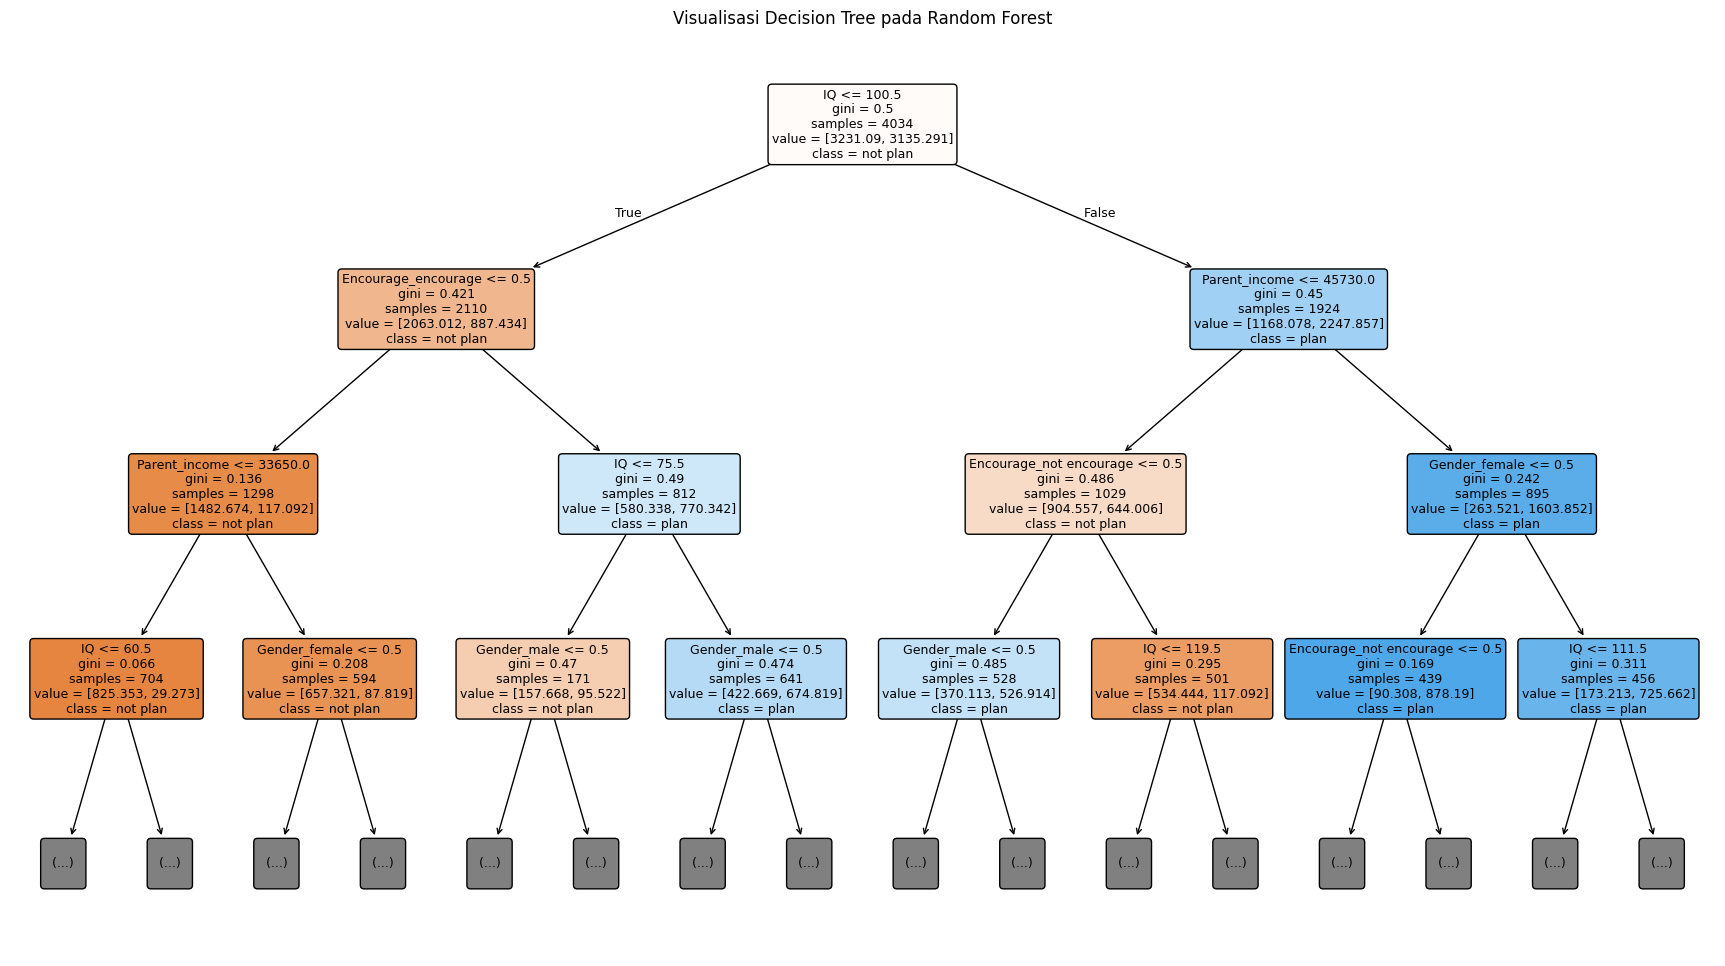

In [28]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Mengambil pohon pertama dari 200 pohon Random Forest
pohon = model.estimators_[0]

# Membuat visualisasi
plt.figure(figsize=(22, 12))

plot_tree(
    pohon,
    feature_names=X_train.columns,
    class_names=[str(kelas) for kelas in model.classes_],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3
)

plt.title("Visualisasi Decision Tree pada Random Forest")
plt.show()

Akurasi: 0.8087 (80.88%)

Classification Report:
              precision    recall  f1-score   support

    not plan       0.84      0.88      0.86      1081
        plan       0.73      0.66      0.69       519

    accuracy                           0.81      1600
   macro avg       0.79      0.77      0.78      1600
weighted avg       0.81      0.81      0.81      1600



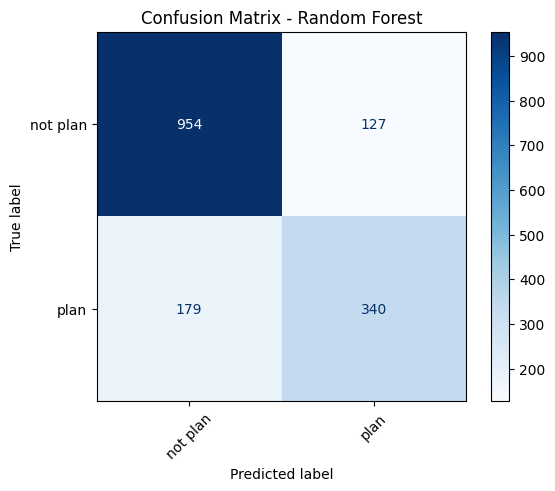

In [23]:
from sklearn.metrics import (
 accuracy_score,
 classification_report,
 confusion_matrix,
 ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
# Prediksi data testing
y_pred = model.predict(X_test)

# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi: {akurasi:.4f} ({akurasi * 100:.2f}%)")

# Evaluasi precision, recall, dan F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(
 confusion_matrix=cm,
 display_labels=model.classes_
)

disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('Confusion Matrix - Random Forest')
plt.show()


In [24]:
import joblib
# Simpan model dan daftar fitur
paket_model = {
 'model': model,
 'fitur': X_train.columns.tolist()
}
joblib.dump(paket_model, 'random_forest_plan.pkl')
print("Model dan daftar fitur berhasil disimpan!")

Model dan daftar fitur berhasil disimpan!


In [25]:
# Load model
paket_model = joblib.load('random_forest_plan.pkl')
model_loaded = paket_model['model']
fitur_model = paket_model['fitur']
print("Model berhasil dimuat kembali!")
print("Fitur model:", fitur_model)


Model berhasil dimuat kembali!
Fitur model: ['Parent_income', 'IQ', 'Gender_female', 'Gender_male', 'Encourage_encourage', 'Encourage_not encourage']


In [26]:
def prediksi_plan(parent_income, iq, gender, encourage):

 # 1. Membuat data baru dengan format asli
 data_baru = pd.DataFrame([{
 'Parent_income': parent_income,
 'IQ': iq,
 'Gender': gender,
 'Encourage': encourage
 }])

 # 2. One-Hot Encoding
 data_encoded = pd.get_dummies(
 data_baru,
 columns=['Gender', 'Encourage'],
 dtype=int
 )

 # 3. Menyamakan kolom dengan data training
 data_encoded = data_encoded.reindex(
 columns=fitur_model,
 fill_value=0
 )

 # 4. Prediksi
 hasil = model_loaded.predict(data_encoded)

 # 5. Probabilitas prediksi
 probabilitas = model_loaded.predict_proba(data_encoded)

 print("Data asli:")
 display(data_baru)

 print("Hasil prediksi Plan:", hasil[0])

 print("\nProbabilitas setiap kelas:")
 for kelas, prob in zip(model_loaded.classes_, probabilitas[0]):
     print(f"{kelas}: {prob:.2%}")

 return hasil[0]


In [27]:
hasil = prediksi_plan(
 parent_income=50000,
 iq=110,
 gender='female',
 encourage='encourage'
)


Data asli:


,Parent_income,IQ,Gender,Encourage
0,50000,110,female,encourage


Hasil prediksi Plan: plan

Probabilitas setiap kelas:
not plan: 9.00%
plan: 91.00%
